In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ai4i2020.csv to ai4i2020.csv


In [ ]:
!pip -q install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Download the dataset from UCI
dataset = fetch_ucirepo(id=601)

X = dataset.data.features.copy()
targets = dataset.data.targets.copy()

# Select the machine failure target
target_column = next(
    col for col in targets.columns
    if "machine failure" in col.lower()
)

y = targets[target_column].astype(int)

# Remove identifier columns if present
id_columns = [
    col for col in X.columns
    if col.lower() in ["udi", "uid", "product id"]
]

X = X.drop(columns=id_columns)

print("Dataset downloaded successfully!")
print("Number of records:", len(X))
print("Number of input features:", len(X.columns))

display(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Dataset downloaded successfully!
Number of records: 10000
Number of input features: 6


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9



Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


Dataset information:


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
count,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
unique,3,NaN,NaN,NaN,NaN,NaN
top,L,NaN,NaN,NaN,NaN,NaN
freq,6000,NaN,NaN,NaN,NaN,NaN
mean,NaN,300.004930,310.005560,1538.776100,39.986910,107.951000
std,NaN,2.000259,1.483734,179.284096,9.968934,63.654147
min,NaN,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,NaN,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,NaN,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,NaN,301.500000,311.100000,1612.000000,46.800000,162.000000



Missing values:
Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
dtype: int64


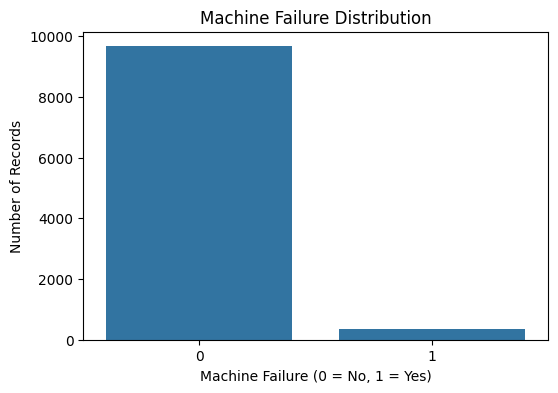

In [ ]:
print("Dataset information:")
display(X.describe(include="all"))

print("\nMissing values:")
print(X.isnull().sum())

plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8000
Testing records: 2000


In [ ]:
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("Preprocessing completed!")
print("Numerical features:", numerical_columns)
print("Categorical features:", categorical_columns)

Preprocessing completed!
Numerical features: ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']
Categorical features: ['Type']


In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced_subsample",
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Machine failure prediction model trained successfully!")

Machine failure prediction model trained successfully!


In [ ]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

print("Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No Failure", "Failure"],
    zero_division=0
))

print("ROC-AUC Score:",
      round(roc_auc_score(y_test, y_probability), 4))

Accuracy: 97.95 %

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.94      0.43      0.59        68

    accuracy                           0.98      2000
   macro avg       0.96      0.71      0.79      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC Score: 0.9654


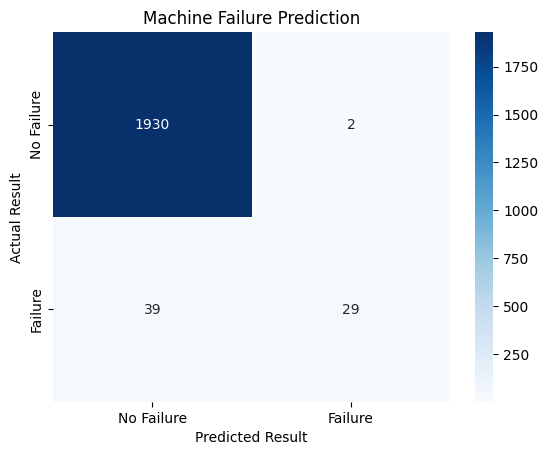

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Machine Failure Prediction")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.show()

,Feature,Importance
2,numeric__Rotational speed,0.306991
3,numeric__Torque,0.289748
4,numeric__Tool wear,0.202533
0,numeric__Air temperature,0.105465
1,numeric__Process temperature,0.074191
6,categorical__Type_L,0.009756
7,categorical__Type_M,0.006945
5,categorical__Type_H,0.004370


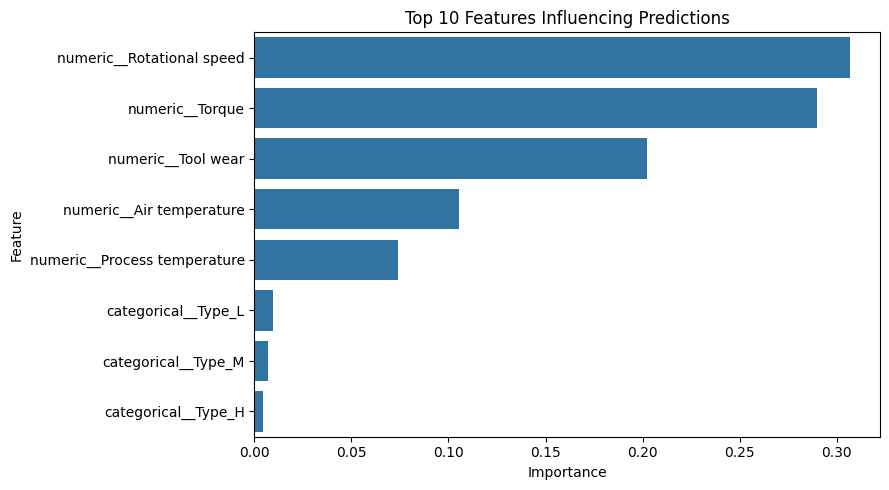

In [ ]:
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Influencing Predictions")
plt.tight_layout()
plt.show()

In [ ]:
new_machine = X.iloc[[0]].copy()

# Set example operating conditions
for col in new_machine.columns:
    name = col.lower()

    if name == "type":
        new_machine.loc[:, col] = "M"
    elif "air temperature" in name:
        new_machine.loc[:, col] = 300.0
    elif "process temperature" in name:
        new_machine.loc[:, col] = 310.0
    elif "rotational speed" in name:
        new_machine.loc[:, col] = 1500
    elif "torque" in name:
        new_machine.loc[:, col] = 45.0
    elif "tool wear" in name:
        new_machine.loc[:, col] = 120

prediction = model.predict(new_machine)[0]
probability = model.predict_proba(new_machine)[0][1]

print("MACHINE ANALYSIS")
print("-------------------------")

if prediction == 1:
    print("Prediction: FAILURE RISK DETECTED")
else:
    print("Prediction: NO FAILURE PREDICTED")

print("Estimated failure probability:",
      round(probability * 100, 2), "%")

print("\nOperating conditions:")
display(new_machine)

MACHINE ANALYSIS
-------------------------
Prediction: NO FAILURE PREDICTED
Estimated failure probability: 0.0 %

Operating conditions:


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,300.0,310.0,1500,45.0,120
